# Activité 4 — Architecture Transformer

Comparaison de trois modèles de prédiction temporelle, essais de modèles préentraînés et réalisation des trois exercices.

Pour reproduire les résultats dans VS Code, ouvrir le dossier du projet, installer les dépendances de `requirements.txt` dans un environnement Python 3.11, choisir ce noyau, puis exécuter toutes les cellules. Le notebook télécharge les poids préentraînés et le jeu UCI au premier besoin. Si le ZIP fourni est déjà disponible, le mettre à côté du notebook sous son nom d’origine ou indiquer son emplacement avec `POWER_ZIP`.

In [1]:
import copy
import math
import os
import re
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "|", device)


class RNNRegresseur(nn.Module):
    def __init__(self, couche):
        super().__init__()
        self.recurrent = couche(1, 32, batch_first=True)
        self.sortie = nn.Linear(32, 1)

    def forward(self, x):
        sequence, _ = self.recurrent(x)
        return self.sortie(sequence[:, -1])


class TransformerRegresseur(nn.Module):
    def __init__(self, longueur, couches=2):
        super().__init__()
        self.projection = nn.Linear(1, 32)
        positions = torch.arange(longueur, dtype=torch.float32).unsqueeze(1)
        frequences = torch.exp(-math.log(10_000) * torch.arange(0, 32, 2) / 32)
        pe = torch.zeros(longueur, 32)
        pe[:, 0::2] = (positions * frequences).sin()
        pe[:, 1::2] = (positions * frequences).cos()
        self.register_buffer("positions", pe.unsqueeze(0))
        couche = nn.TransformerEncoderLayer(
            d_model=32, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=couches)
        self.sortie = nn.Linear(32, 1)

    def forward(self, x):
        representations = self.projection(x) + self.positions[:, :x.shape[1]]
        return self.sortie(self.encodeur(representations)[:, -1])


def lots(X, y, masque, melanger=False, taille=128):
    return DataLoader(TensorDataset(X[masque], y[masque]), batch_size=taille, shuffle=melanger)


@torch.inference_mode()
def predire(modele, ensemble):
    modele.eval()
    predictions, cibles = [], []
    for x, y in ensemble:
        predictions.append(modele(x.to(device)).cpu())
        cibles.append(y)
    return torch.cat(predictions).flatten(), torch.cat(cibles).flatten()


def entrainer_regression(modele, train, validation, epochs, lr=0.001):
    modele.to(device)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    historique, minimum = [], float("inf")
    for epoch in range(epochs):
        modele.train()
        for x, y in train:
            optimiseur.zero_grad()
            perte = F.mse_loss(modele(x.to(device)), y.to(device))
            perte.backward()
            optimiseur.step()
        estimations, cibles = predire(modele, validation)
        mse = F.mse_loss(estimations, cibles).item()
        historique.append(mse)
        if mse < minimum:
            minimum, meilleure_epoque = mse, epoch + 1
            meilleurs_poids = copy.deepcopy(modele.state_dict())
    modele.load_state_dict(meilleurs_poids)
    return historique, meilleure_epoque


def mesures(predictions, cibles):
    erreurs = predictions - cibles
    return erreurs.abs().mean().item(), erreurs.square().mean().sqrt().item()

PyTorch 2.15.0 | cpu


## Première partie — Prédire le prochain point de sin(x)

Chaque entrée contient exactement dix valeurs déjà observées. On découpe par date de la cible (70 % / 15 % / 15 %) et on compare RNN, LSTM et Transformer sur les mêmes cibles. Chaque entraînement est sélectionné sur la validation. La persistance sert de point de comparaison.

Entrée : (1790, 10, 1) | cible : (1790, 1)
RNN          | époque choisie 24 | MAE 0.01287 | RMSE 0.01444
LSTM         | époque choisie 27 | MAE 0.00625 | RMSE 0.00723
Transformer  | époque choisie 19 | MAE 0.00506 | RMSE 0.00638
Persistance  | MAE 0.02273


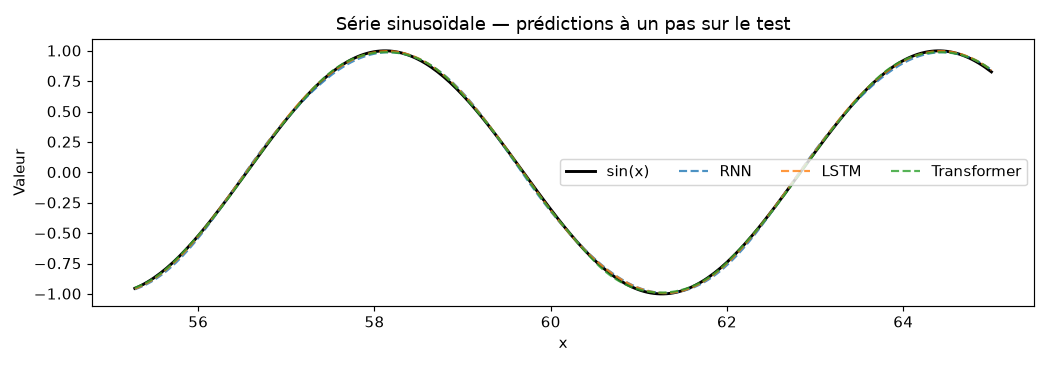

In [2]:
abscisses = torch.linspace(0, 65, 1800)
sinus = torch.sin(abscisses)
fenetres = sinus.unfold(0, 11, 1)
X_sinus, y_sinus = fenetres[:, :10].unsqueeze(-1), fenetres[:, 10:]
indices = torch.arange(10, len(sinus))
fin_entrainement = int(0.70 * len(sinus))
fin_validation = int(0.85 * len(sinus))
train_sinus = lots(X_sinus, y_sinus, indices < fin_entrainement, True, 64)
val_sinus = lots(X_sinus, y_sinus, (indices >= fin_entrainement) & (indices < fin_validation))
test_sinus = lots(X_sinus, y_sinus, indices >= fin_validation)
print("Entrée :", tuple(X_sinus.shape), "| cible :", tuple(y_sinus.shape))

models_sinus = {
    "RNN": RNNRegresseur(nn.RNN),
    "LSTM": RNNRegresseur(nn.LSTM),
    "Transformer": TransformerRegresseur(10),
}
sin_predictions = {}
for nom, modele in models_sinus.items():
    _, meilleure = entrainer_regression(modele, train_sinus, val_sinus, epochs=28, lr=0.002)
    estimation, reference = predire(modele, test_sinus)
    sin_predictions[nom] = estimation
    mae, rmse = mesures(estimation, reference)
    print(f"{nom:12} | époque choisie {meilleure:2d} | MAE {mae:.5f} | RMSE {rmse:.5f}")

persistance = X_sinus[indices >= fin_validation, -1, 0]
print(f"Persistance  | MAE {mesures(persistance, reference)[0]:.5f}")
plt.figure(figsize=(10, 3.5))
plt.plot(abscisses[fin_validation:], reference, color="black", label="sin(x)", linewidth=2)
for nom, valeurs in sin_predictions.items():
    plt.plot(abscisses[fin_validation:], valeurs, "--", label=nom, alpha=0.8)
plt.xlabel("x")
plt.ylabel("Valeur")
plt.title("Série sinusoïdale — prédictions à un pas sur le test")
plt.legend(ncol=4)
plt.tight_layout()
plt.show()

### GPT et BERT préentraînés

Les exemples utilisent [DistilGPT2](https://huggingface.co/distilbert/distilgpt2) et [DistilBERT](https://huggingface.co/distilbert/distilbert-base-uncased), deux variantes légères des architectures du cours. Les prompts sont en anglais, comme les corpus de ces points de contrôle. GPT ajoute des tokens à la fin. BERT attribue des probabilités aux candidats à une position masquée.

In [3]:
from transformers import AutoModelForCausalLM, AutoModelForMaskedLM, AutoTokenizer

gpt_id = "distilbert/distilgpt2"
gpt_tok = AutoTokenizer.from_pretrained(gpt_id)
gpt_demo = AutoModelForCausalLM.from_pretrained(gpt_id).eval()
amorce = "Artificial intelligence can help scientists"
entree = gpt_tok(amorce, return_tensors="pt")
with torch.inference_mode():
    sortie = gpt_demo.generate(
        **entree, max_new_tokens=18, do_sample=False, pad_token_id=gpt_tok.eos_token_id
    )
suite = gpt_tok.decode(sortie[0, entree["input_ids"].shape[1]:], skip_special_tokens=True)
assert sortie.shape[1] > entree["input_ids"].shape[1]
print("Amorce :", amorce)
print("Suite :", suite)
del gpt_demo

Amorce : Artificial intelligence can help scientists
Suite :  to better understand the world around them.












In [4]:
bert_id = "distilbert/distilbert-base-uncased"
bert_tok = AutoTokenizer.from_pretrained(bert_id)
bert_demo = AutoModelForMaskedLM.from_pretrained(bert_id).eval()
phrase = f"Rabat is the {bert_tok.mask_token} of Morocco."
entree = bert_tok(phrase, return_tensors="pt")
masque = entree["input_ids"].eq(bert_tok.mask_token_id)
assert masque.sum().item() == 1
with torch.inference_mode():
    probas = bert_demo(**entree).logits[masque].softmax(-1).squeeze(0)
scores, indices_bert = probas.topk(5)
print("Texte :", phrase)
for score, numero in zip(scores, indices_bert):
    mot = bert_tok.decode([numero.item()]).strip()
    print(f"{score.item():.2%} | {phrase.replace(bert_tok.mask_token, mot)}")
del bert_demo

Texte : Rabat is the [MASK] of Morocco.
99.52% | Rabat is the capital of Morocco.
0.06% | Rabat is the province of Morocco.
0.05% | Rabat is the prefecture of Morocco.
0.05% | Rabat is the birthplace of Morocco.
0.03% | Rabat is the southernmost of Morocco.


## Deuxième partie — Exercice 1. Consommation électrique

Source : Georges Hebrail et Alice Berard, [Individual Household Electric Power Consumption](https://doi.org/10.24432/C58K54), UCI, CC BY 4.0. Le ZIP est lu directement. La variable `Global_active_power` représente une puissance moyenne en kW. Les heures avec moins de 45 mesures disponibles sont écartées. Les fenêtres avec un trou sont exclues. Les statistiques de normalisation proviennent exclusivement de la portion d’entraînement.

In [5]:
nom_zip = "individual+household+electric+power+consumption.zip"
zip_path = Path(os.environ.get("POWER_ZIP", nom_zip))
if not zip_path.is_file():
    if "POWER_ZIP" in os.environ:
        raise FileNotFoundError(zip_path)
    url = "https://archive.ics.uci.edu/static/public/235/" + nom_zip
    temporaire = zip_path.with_suffix(".download")
    urlretrieve(url, temporaire)
    temporaire.replace(zip_path)

with ZipFile(zip_path) as archive:
    with archive.open("household_power_consumption.txt") as fichier:
        df = pd.read_csv(
            fichier, sep=";", usecols=["Date", "Time", "Global_active_power"], na_values="?"
        )
temps = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
puissance = pd.Series(df["Global_active_power"].to_numpy(), index=pd.DatetimeIndex(temps))
print("Mesures minute :", len(puissance))
del df, temps
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)
lim_train, lim_val = int(len(serie) * 0.70), int(len(serie) * 0.85)
moyenne, ecart_type = serie.iloc[:lim_train].mean(), serie.iloc[:lim_train].std()
normalisee = ((serie - moyenne) / ecart_type).to_numpy()
fenetres = np.lib.stride_tricks.sliding_window_view(normalisee, 25)
valides = np.isfinite(fenetres).all(axis=1)
heures_cibles = np.arange(24, len(serie))[valides]
assert ((serie.index[1:] - serie.index[:-1]) == pd.Timedelta(hours=1)).all()
X = torch.tensor(fenetres[valides, :24], dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(fenetres[valides, 24:], dtype=torch.float32)
train = lots(X, y, heures_cibles < lim_train, True)
validation = lots(X, y, (heures_cibles >= lim_train) & (heures_cibles < lim_val))
test = lots(X, y, heures_cibles >= lim_val)
print("Fenêtres train / validation / test :", *(len(s.dataset) for s in (train, validation, test)))
print("Forme d’une fenêtre :", tuple(X.shape[1:]))

Mesures minute : 2075259
Fenêtres train / validation / test : 23805 5054 4932
Forme d’une fenêtre : (24, 1)


Époque choisie sur la validation : 7
MSE de validation par époque : [0.4176, 0.408, 0.3935, 0.3986, 0.3995, 0.3986, 0.3851, 0.3884]
                       MAE (kW)  RMSE (kW)
Modèle                                    
Transformer              0.3377     0.4916
Persistance              0.3892     0.5884
Référence journalière    0.5133     0.7639
Meilleur modèle pour MAE (kW) : Transformer
Meilleur modèle pour RMSE (kW) : Transformer


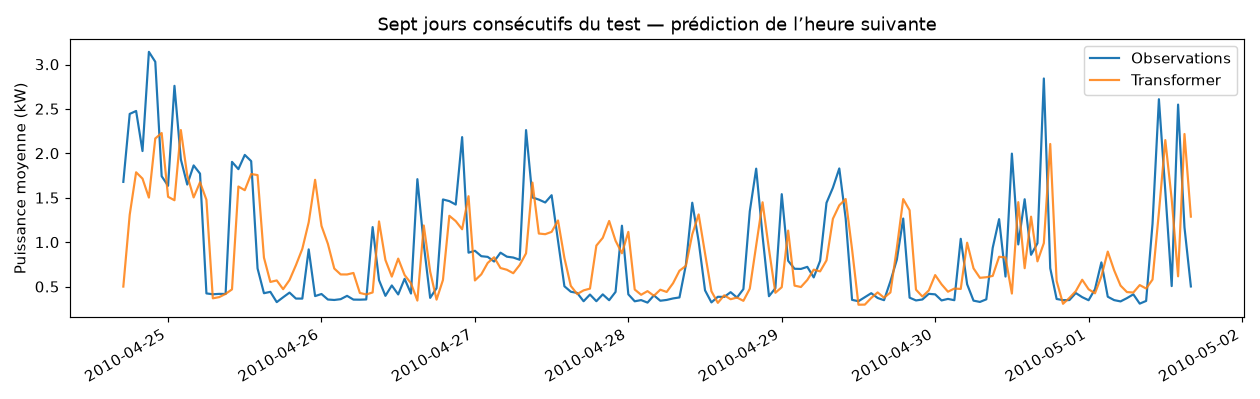

In [6]:
class EnergyTransformer(TransformerRegresseur):
    def __init__(self):
        super().__init__(longueur=24, couches=2)


energie = EnergyTransformer()
hist, meilleure = entrainer_regression(energie, train, validation, epochs=8)
pred_norm, cibles_norm = predire(energie, test)
X_test = X[heures_cibles >= lim_val]
predictions = pred_norm * ecart_type + moyenne
observations = cibles_norm * ecart_type + moyenne
refs = {
    "Transformer": predictions,
    "Persistance": X_test[:, -1, 0] * ecart_type + moyenne,
    "Référence journalière": X_test[:, 0, 0] * ecart_type + moyenne,
}
tableau = pd.DataFrame(
    [(nom, *mesures(pred, observations)) for nom, pred in refs.items()],
    columns=["Modèle", "MAE (kW)", "RMSE (kW)"],
).set_index("Modèle")
print("Époque choisie sur la validation :", meilleure)
print("MSE de validation par époque :", [round(v, 4) for v in hist])
print(tableau.to_string(float_format=lambda v: f"{v:.4f}"))
for mesure in tableau.columns:
    gagnant = tableau[mesure].idxmin()
    print(f"Meilleur modèle pour {mesure} : {gagnant}")

heures_test = heures_cibles[heures_cibles >= lim_val]
blocs_contigus = np.split(np.arange(len(heures_test)), np.flatnonzero(np.diff(heures_test) != 1) + 1)
semaine = next(bloc[:168] for bloc in blocs_contigus if len(bloc) >= 168)
dates = serie.index[heures_test[semaine]]
assert dates[-1] - dates[0] == pd.Timedelta(hours=167)
plt.figure(figsize=(12, 3.8))
plt.plot(dates, observations[semaine], label="Observations")
plt.plot(dates, predictions[semaine], label="Transformer", alpha=0.85)
plt.ylabel("Puissance moyenne (kW)")
plt.title("Sept jours consécutifs du test — prédiction de l’heure suivante")
plt.legend()
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.show()

### Interprétation de l’exercice 1

Dans l’exécution enregistrée, le Transformer devance la persistance et la référence journalière sur les deux métriques. Il obtient une MAE de 0,3377 kW et une RMSE de 0,4916 kW.
- Le tableau compare les trois modèles sur les mêmes heures cibles. La persistance utilise la mesure à H−1 et la référence journalière celle à H−24. Toutes les prédictions utilisent des mesures observées, sans propagation de leurs propres erreurs.
- Une fenêtre de 168 heures rend accessible le même créneau de la semaine précédente. Son intérêt doit être mesuré sur la validation, avec le même test chronologique et une référence à H−168. Elle augmente aussi le coût de l’attention et rend plus probable la présence d’un trou. Cette variante n’est pas entraînée ici.
- Le jour et l’heure donnent des repères sur les horaires domestiques. Des couples sinus/cosinus évitent une discontinuité entre 23 h et minuit ou entre dimanche et lundi.
- Calculer la moyenne et l’écart type sur le test fournirait au modèle de l’information provenant du futur.
- Pour obtenir l’énergie horaire, intégrer la puissance : pour des minutes complètes, sommer les kW moyens de chaque minute et diviser par 60 pour obtenir des kWh. Pour une heure incomplète, il faut rejeter l’heure ou définir une règle d’imputation explicite.

## Exercice 2. Mini-GPT caractère par caractère

Le corpus original est fourni dans `corpus.txt`. On déplace les cibles d’un caractère. Le modèle utilise une fenêtre de 64 caractères, deux blocs pré-normalisés, quatre têtes et un MLP 64 → 256 → 64. Le masque triangulaire empêche une position d’accéder aux caractères futurs.

In [7]:
texte = Path("corpus.txt").read_text(encoding="utf-8")
caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = dict(enumerate(caracteres))
tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)
longueur = 64


class BlocGPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1 = nn.LayerNorm(64)
        self.attention = nn.MultiheadAttention(64, 4, batch_first=True)
        self.norm2 = nn.LayerNorm(64)
        self.mlp = nn.Sequential(nn.Linear(64, 256), nn.GELU(), nn.Linear(256, 64))

    def forward(self, x, masque):
        h = self.norm1(x)
        x = x + self.attention(h, h, h, attn_mask=masque, need_weights=False)[0]
        return x + self.mlp(self.norm2(x))


class MiniGPT(nn.Module):
    def __init__(self, vocabulaire):
        super().__init__()
        self.tokens = nn.Embedding(vocabulaire, 64)
        self.positions = nn.Embedding(longueur, 64)
        self.blocs = nn.ModuleList([BlocGPT(), BlocGPT()])
        self.tete = nn.Sequential(nn.LayerNorm(64), nn.Linear(64, vocabulaire))
        masque = torch.ones(longueur, longueur, dtype=torch.bool).triu(diagonal=1)
        self.register_buffer("masque", masque)

    def forward(self, ids):
        taille = ids.size(1)
        positions = torch.arange(taille, device=ids.device)
        x = self.tokens(ids) + self.positions(positions)
        for bloc in self.blocs:
            x = bloc(x, self.masque[:taille, :taille])
        return self.tete(x)


def lot_gpt(flux, batch=24):
    debuts = torch.randint(len(flux) - longueur, (batch,))
    ids = debuts[:, None] + torch.arange(longueur)[None, :]
    return flux[ids].to(device), flux[ids + 1].to(device)


mini_gpt = MiniGPT(len(caracteres)).to(device)
optimizer = torch.optim.AdamW(mini_gpt.parameters(), lr=0.001)
coupe = int(0.90 * len(tokens))
morceau_train, morceau_val = tokens[:coupe], tokens[coupe:]
torch.manual_seed(123)
val_x, val_y = lot_gpt(morceau_val, batch=64)
print("Caractères du corpus :", len(tokens), "| taille du vocabulaire :", len(caracteres))
for etape in range(1, 501):
    mini_gpt.train()
    x, y = lot_gpt(morceau_train)
    optimizer.zero_grad()
    logits = mini_gpt(x)
    perte = F.cross_entropy(logits.flatten(0, 1), y.flatten())
    perte.backward()
    optimizer.step()
    if etape == 1 or etape % 100 == 0:
        mini_gpt.eval()
        with torch.inference_mode():
            perte_val = F.cross_entropy(mini_gpt(val_x).flatten(0, 1), val_y.flatten())
        print(f"Étape {etape:3d} | train {perte.item():.3f} | val {perte_val.item():.3f}")
print("Formes :", tuple(x.shape), tuple(logits.shape), tuple(y.shape))

Caractères du corpus : 5096 | taille du vocabulaire : 48
Étape   1 | train 4.038 | val 3.906
Étape 100 | train 2.362 | val 2.347
Étape 200 | train 2.240 | val 2.235
Étape 300 | train 2.108 | val 2.178
Étape 400 | train 2.023 | val 2.094
Étape 500 | train 1.761 | val 2.018
Formes : (24, 64) (24, 64, 48) (24, 64)


In [8]:
@torch.inference_mode()
def generer_caracteres(modele, amorce, temperature, n=200):
    modele.eval()
    rng = torch.Generator().manual_seed(42)
    ids = torch.tensor([[stoi[c] for c in amorce]], device=device)
    for _ in range(n):
        logits = modele(ids[:, -longueur:])[0, -1]
        p = (logits / temperature).softmax(dim=-1).cpu()
        prochain = torch.multinomial(p, 1, generator=rng).to(device)
        ids = torch.cat([ids, prochain.reshape(1, 1)], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())


mini_gpt.eval()
with torch.inference_mode():
    ids = tokens[:longueur].to(device).unsqueeze(0)
    modifies = ids.clone()
    modifies[0, 40] = (modifies[0, 40] + 1) % len(caracteres)
    ecart_causal = (mini_gpt(ids)[:, :40] - mini_gpt(modifies)[:, :40]).abs().max().item()
assert ecart_causal < 1e-5
print(f"Écart maximal aux positions antérieures : {ecart_causal:.2e}")

amorce = "Lina a "
for temperature in (0.5, 1.0, 1.5):
    generation = generer_caracteres(mini_gpt, amorce, temperature)
    assert len(generation) - len(amorce) == 200
    print(f"\nTempérature {temperature} — 200 nouveaux caractères :\n{generation}")

Écart maximal aux positions antérieures : 0.00e+00

Température 0.5 — 200 nouveaux caractères :
Lina a la te la conté l'achait lavermis du de lait la les au parges etre les des la rorges les ets oures res de des andes bont proille boures la bes res de des des déc bous des etes oures pont des ont ples d

Température 1.0 — 200 nouveaux caractères :
Lina a là ter béclermain la cet. Le a ple feraivane. Le aouié ac atra de un etes la rêt pomà, untet crmilr de mêmout d'un, d bnimpe la brert pla bet chande crs lut céc, lâjau pacumien proun plorchesit pavent

Température 1.5 — 200 nouveaux caractères :
Lina a làtéer béclermplé la cet. A

Lioyemf
Auivane. Le souié ac la vend un jdes la rêcaidexais out omme resdémê

xnc, pp, d Dépromala brermaulé.
Uèlà Unde crs lut céc, lâjt quancer buie une lorcviontbabl'ut


Sans le masque, l’entraînement pourrait lire le caractère cible dans la suite fournie et sous-estimer l’erreur réelle de génération. Décaler les cibles aligne chaque prédiction avec le prochain caractère. Une température basse concentre la probabilité sur les choix les plus probables, tandis qu’une température haute rend le tirage plus diversifié. Les sorties montrent aussi la limite d’un corpus court : le texte peut répéter des passages ou perdre sa cohérence.

## Exercice 3. Mini-BERT avec masquage de mots

Un petit corpus synthétique est construit à partir de thèmes et de contextes. Les phrases entières de validation sont réservées avant la construction du vocabulaire. Le modèle est bidirectionnel et la perte porte uniquement sur les positions sélectionnées.

In [9]:
PAD, UNK, CLS, SEP, MASK = range(5)
longueur_bert = 32
special = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
sujets = {
    "le chat": ["dort", "ronronne", "observe"],
    "le chien": ["aboie", "court", "attend"],
    "le jardinier": ["arrose", "plante", "taille"],
    "la cuisinière": ["prépare", "mélange", "goûte"],
    "la musicienne": ["joue", "chante", "répète"],
    "le facteur": ["marche", "distribue", "sonne"],
}
contextes = ["près de la porte", "dans le jardin", "dans la cour", "près de la fenêtre"]
moments = ["ce matin", "chaque soir", "après la pluie", "avant midi", "le dimanche"]
phrases = [
    f"{moment} {sujet} {verbe} {contexte}"
    for sujet, verbes in sujets.items()
    for verbe in verbes
    for contexte in contextes
    for moment in moments
]
rng = np.random.default_rng(42)
ordre = rng.permutation(len(phrases))
corpus_train = [phrases[i] for i in ordre[:288]]
corpus_val = [phrases[i] for i in ordre[288:]]
assert not set(corpus_train) & set(corpus_val)
vocabulaire = special + sorted({mot for phrase in corpus_train for mot in phrase.split()})
vocab = {mot: i for i, mot in enumerate(vocabulaire)}


def encoder_phrase(phrase):
    mots = phrase.lower().split()[:longueur_bert - 2]
    ids = [CLS] + [vocab.get(mot, UNK) for mot in mots] + [SEP]
    return ids + [PAD] * (longueur_bert - len(ids))


def masquer(ids, generateur):
    ordinaires = ids >= len(special)
    selection = ordinaires & (torch.rand(ids.shape, generator=generateur) < 0.15)
    for i in torch.where(ordinaires.any(1) & ~selection.any(1))[0]:
        candidats = ordinaires[i].nonzero().flatten()
        selection[i, candidats[torch.randint(len(candidats), (), generator=generateur)]] = True
    tirage = torch.rand(ids.shape, generator=generateur)
    entrees = ids.clone()
    entrees[selection & (tirage < 0.8)] = MASK
    ales = selection & (tirage >= 0.8) & (tirage < 0.9)
    entrees[ales] = torch.randint(len(special), len(vocab), (int(ales.sum()),), generator=generateur)
    cibles = ids.masked_fill(~selection, -100)
    return entrees, cibles, ids.eq(PAD)


class MiniBERT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens = nn.Embedding(len(vocab), 64, padding_idx=PAD)
        self.positions = nn.Embedding(longueur_bert, 64)
        bloc = nn.TransformerEncoderLayer(64, 4, 256, dropout=0.1, batch_first=True)
        self.encodeur = nn.TransformerEncoder(bloc, 2, enable_nested_tensor=False)
        self.sortie = nn.Linear(64, len(vocab))

    def forward(self, ids, padding):
        positions = torch.arange(ids.size(1), device=ids.device)
        h = self.tokens(ids) + self.positions(positions)
        return self.sortie(self.encodeur(h, src_key_padding_mask=padding))


train_ids = torch.tensor([encoder_phrase(p) for p in corpus_train])
val_ids = torch.tensor([encoder_phrase(p) for p in corpus_val])
loader = DataLoader(train_ids, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(10))
val_in, val_cibles, val_padding = masquer(val_ids, torch.Generator().manual_seed(100))
assert (val_cibles.ne(-100).any(1)).all()
assert (val_ids[val_cibles.ne(-100)] >= len(special)).all()
print("Phrases train / validation :", len(train_ids), len(val_ids), "| vocabulaire :", len(vocab))

mini_bert = MiniBERT().to(device)
optimiseur = torch.optim.AdamW(mini_bert.parameters(), lr=0.001)
generateur = torch.Generator().manual_seed(11)
for epoque in range(1, 22):
    mini_bert.train()
    for ids in loader:
        entrees, cibles, padding = masquer(ids, generateur)
        optimiseur.zero_grad()
        logits = mini_bert(entrees.to(device), padding.to(device))
        perte = F.cross_entropy(logits.flatten(0, 1), cibles.flatten().to(device), ignore_index=-100)
        perte.backward()
        optimiseur.step()
    if epoque in (1, 5, 10, 15, 21):
        mini_bert.eval()
        with torch.inference_mode():
            logits_val = mini_bert(val_in.to(device), val_padding.to(device)).cpu()
            selection = val_cibles.ne(-100)
            exactitude = (logits_val.argmax(-1)[selection] == val_cibles[selection]).float().mean()
            perte_val = F.cross_entropy(logits_val[selection], val_cibles[selection])
        print(f"Époque {epoque:2d} | perte val {perte_val.item():.3f} | accuracy val {exactitude.item():.1%}")
print("Mots sélectionnés dans la validation :", selection.sum().item())

Phrases train / validation : 288 72 | vocabulaire : 47
Époque  1 | perte val 3.068 | accuracy val 27.5%
Époque  5 | perte val 2.024 | accuracy val 46.1%
Époque 10 | perte val 1.173 | accuracy val 67.6%
Époque 15 | perte val 0.823 | accuracy val 74.5%
Époque 21 | perte val 0.677 | accuracy val 77.5%
Mots sélectionnés dans la validation : 102


In [10]:
mini_bert.eval()
with torch.inference_mode():
    ids = val_in[:4].to(device)
    padding = val_padding[:4].to(device)
    ids_modifies = ids.clone()
    ids_modifies[padding] = len(special)
    original = mini_bert(ids, padding)
    modifie = mini_bert(ids_modifies, padding)
    ecart = (original[~padding] - modifie[~padding]).abs().max().item()
assert ecart < 1e-5
print(f"Écart maximal hors des positions de padding : {ecart:.2e}")

for ligne, position in val_in.eq(MASK).nonzero()[:5]:
    contexte = " ".join(vocabulaire[i] for i in val_in[ligne].tolist() if i not in (PAD, CLS, SEP))
    probabilites = logits_val[ligne, position].softmax(-1)
    top3 = (probabilites[len(special):].topk(3).indices + len(special)).tolist()
    print(contexte)
    print("Attendu :", vocabulaire[val_cibles[ligne, position]], "| Top 3 :",
          [(vocabulaire[i], f"{probabilites[i].item():.1%}") for i in top3])

Écart maximal hors des positions de padding : 0.00e+00
ce matin le jardinier arrose dans [MASK] jardin
Attendu : le | Top 3 : [('le', '97.4%'), ('la', '0.7%'), ('ce', '0.4%')]
après [MASK] pluie le jardinier taille près de [MASK] fenêtre
Attendu : la | Top 3 : [('la', '98.0%'), ('midi', '0.2%'), ('soir', '0.2%')]
après [MASK] pluie le jardinier taille près de [MASK] fenêtre
Attendu : la | Top 3 : [('la', '97.7%'), ('de', '0.4%'), ('le', '0.3%')]
après la pluie le facteur sonne dans [MASK] jardin
Attendu : le | Top 3 : [('le', '92.1%'), ('la', '5.0%'), ('ce', '0.3%')]
après la pluie le chien attend près [MASK] la fenêtre
Attendu : de | Top 3 : [('de', '96.9%'), ('près', '0.7%'), ('la', '0.5%')]


BERT peut regarder à droite parce que son encodeur est bidirectionnel et applique uniquement le masque de padding. La perte sur les positions sélectionnées oblige le modèle à apprendre à reconstruire les mots à partir du contexte. Les tokens sélectionnés mais laissés inchangés participent aussi à cette perte. Une séquence masquée se complète avec un contexte existant. GPT, lui, définit directement un prochain caractère à générer après le préfixe.

### Limite de la validation du mini-BERT

L’exactitude enregistrée est de 77,5 % sur 102 positions de validation. Les phrases réservées sont distinctes, mais partagent la même structure synthétique que les phrases d’entraînement. Ce résultat mesure la reconstruction dans ce corpus.